# Part 2 — CLIP for Image–Text Matching and Zero-Shot Classification

Frozen CLIP `ViT-B/32` (`openai/clip-vit-base-patch32`) on the same 20 images as Part 1.

In [1]:
import json
import os
import platform
import warnings

os.environ.setdefault("HF_HUB_VERBOSITY", "error")
os.environ.setdefault("HF_HUB_DISABLE_SYMLINKS_WARNING", "1")  # Windows-only cache notice, not relevant to results
warnings.filterwarnings("ignore", message=".*unauthenticated requests.*")
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
import transformers
from PIL import Image, ImageOps
from transformers import CLIPModel, CLIPProcessor

ROOT = Path.cwd()
DATA = ROOT / "data"
OUT = ROOT / "outputs" / "part2"
OUT.mkdir(parents=True, exist_ok=True)

torch.manual_seed(0)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

CHECKPOINT = "openai/clip-vit-base-patch32"
model = CLIPModel.from_pretrained(CHECKPOINT).to(device).eval()
processor = CLIPProcessor.from_pretrained(CHECKPOINT)

try:  # record the exact revision of the checkpoint on the Hugging Face Hub
    from huggingface_hub import HfApi
    checkpoint_commit = HfApi().model_info(CHECKPOINT).sha
except Exception as exc:
    checkpoint_commit = f"unavailable ({type(exc).__name__})"

env = {
    "python": platform.python_version(),
    "torch": torch.__version__,
    "transformers": transformers.__version__,
    "numpy": np.__version__,
    "pillow": Image.__version__,
    "device": str(device),
    "processor": platform.processor(),
    "os": platform.platform(),
    "checkpoint": CHECKPOINT,
    "checkpoint_commit": checkpoint_commit,
    "learned_logit_scale_exp": round(model.logit_scale.exp().item(), 4),
}
(OUT / "environment.json").write_text(json.dumps(env, indent=2))
env

Loading weights:   0%|          | 0/398 [00:00<?, ?it/s]

{'python': '3.13.2',
 'torch': '2.14.0+cpu',
 'transformers': '5.19.0',
 'numpy': '2.2.2',
 'pillow': '12.3.0',
 'device': 'cpu',
 'processor': 'Intel64 Family 6 Model 165 Stepping 2, GenuineIntel',
 'os': 'Windows-11-10.0.26300-SP0',
 'checkpoint': 'openai/clip-vit-base-patch32',
 'checkpoint_commit': '3d74acf9a28c67741b2f4f2ea7635f0aaf6f0268',
 'learned_logit_scale_exp': 100.0}

In [2]:
# The checkpoint's own image preprocessing (applied by `processor` below)
ip = processor.image_processor
print("resize shortest side to:", ip.size, "| centre crop:", ip.crop_size)
print("rescale by 1/255:", ip.do_rescale, "| normalize mean:", ip.image_mean, "std:", ip.image_std)
print("text: CLIP BPE tokenizer, context length", processor.tokenizer.model_max_length)

resize shortest side to: SizeDict(height=None, width=None, longest_edge=None, shortest_edge=224, max_height=None, max_width=None, min_pixels=None, max_pixels=None) | centre crop: SizeDict(height=224, width=224, longest_edge=None, shortest_edge=None, max_height=None, max_width=None, min_pixels=None, max_pixels=None)
rescale by 1/255: True | normalize mean: (0.48145466, 0.4578275, 0.40821073) std: (0.26862954, 0.26130258, 0.27577711)
text: CLIP BPE tokenizer, context length 77


## Data and encoders

The encoders return raw embeddings and everything after that is done by hand; image embeddings are cached in `outputs/part2/image_embeddings.npz`.

In [3]:
sources = pd.read_csv(DATA / "image_sources.csv")
CATEGORIES = list(dict.fromkeys(sources.category))          # folder names, in dataset order
NAMES = {c: c.replace("_", " ") for c in CATEGORIES}          # text used inside prompts
image_names = [Path(f).stem for f in sources.file]
true = np.array([CATEGORIES.index(c) for c in sources.category])
print(CATEGORIES, "| images:", len(sources))


def load_images(files):
    return [Image.open(ROOT / f).convert("RGB") for f in files]


@torch.no_grad()
def encode_images(images, batch_size=4):
    out = []
    for i in range(0, len(images), batch_size):
        pixels = processor(images=images[i:i + batch_size], return_tensors="pt")["pixel_values"].to(device)
        pooled = model.vision_model(pixel_values=pixels).pooler_output
        out.append(model.visual_projection(pooled).cpu())
    return torch.cat(out)


@torch.no_grad()
def encode_texts(texts):
    tokens = processor(text=texts, padding=True, return_tensors="pt").to(device)
    pooled = model.text_model(input_ids=tokens["input_ids"], attention_mask=tokens["attention_mask"]).pooler_output
    return model.text_projection(pooled).cpu()


cache = OUT / "image_embeddings.npz"
if cache.exists() and list(np.load(cache, allow_pickle=False)["files"]) == list(sources.file):
    image_emb = torch.from_numpy(np.load(cache, allow_pickle=False)["embeddings"])
    print("loaded cached image embeddings", tuple(image_emb.shape))
else:
    image_emb = encode_images(load_images(sources.file))
    np.savez(cache, embeddings=image_emb.numpy(), files=np.array(sources.file, dtype=str))
    print("computed and cached image embeddings", tuple(image_emb.shape))

['golden_retriever', 'zebra', 'school_bus', 'banana', 'acoustic_guitar'] | images: 20
computed and cached image embeddings (20, 512)


## Task 1 — Implement the similarity calculation

Normalize the embeddings, take dot products (cosine similarity), multiply by the learned scale (logits), then softmax over the texts.

In [4]:
def l2_normalize(x, eps=1e-12):
    """Scale each row to unit Euclidean length."""
    return x / x.norm(dim=-1, keepdim=True).clamp_min(eps)


def cosine_similarity_matrix(a, b):
    """(n, d) and (m, d) raw embeddings -> (n, m) matrix of cosine similarities."""
    return l2_normalize(a) @ l2_normalize(b).T


def similarities_to_logits(sim, logit_scale):
    """CLIP stores log(scale) as a parameter; the multiplier is its exponential."""
    return logit_scale.exp() * sim


def softmax_rows(logits):
    """Softmax over the candidate texts (columns) for each image (row)."""
    shifted = logits - logits.max(dim=1, keepdim=True).values  # subtract row max for numerical stability
    e = shifted.exp()
    return e / e.sum(dim=1, keepdim=True)


def classify(image_embeddings, text_embeddings):
    sim = cosine_similarity_matrix(image_embeddings, text_embeddings)
    logits = similarities_to_logits(sim, model.logit_scale.detach().cpu())
    probs = softmax_rows(logits)
    return sim, logits, probs, probs.argmax(dim=1)


# unit tests for the hand-written pieces
_v = torch.tensor([[3.0, 4.0], [0.0, 2.0]])
assert torch.allclose(l2_normalize(_v).norm(dim=1), torch.ones(2))
assert torch.allclose(cosine_similarity_matrix(_v, _v).diag(), torch.ones(2))
assert torch.allclose(cosine_similarity_matrix(_v, _v)[0, 1], torch.tensor(0.8))  # (3*0 + 4*2) / (5*2)
_l = torch.randn(4, 6)
assert torch.allclose(softmax_rows(_l), torch.softmax(_l, dim=1), atol=1e-6)
assert torch.allclose(softmax_rows(_l).sum(1), torch.ones(4))
print("helper checks passed")

helper checks passed


In [5]:
def article(noun):
    return "an" if noun[0].lower() in "aeiou" else "a"


prompts = [f"a photo of {article(NAMES[c])} {NAMES[c]}" for c in CATEGORIES]
text_emb = encode_texts(prompts)
sim, logits, probs, pred = classify(image_emb, text_emb)

print("prompts:", prompts)
print("image embeddings:", tuple(image_emb.shape), "| text embeddings:", tuple(text_emb.shape))
print("norms before normalization (first 3 images):", image_emb.norm(dim=1)[:3].numpy().round(2))
print("norms after normalization  (first 3 images):", l2_normalize(image_emb).norm(dim=1)[:3].numpy().round(4))
print(f"learned scale exp(logit_scale) = {model.logit_scale.exp().item():.4f}")

prompts: ['a photo of a golden retriever', 'a photo of a zebra', 'a photo of a school bus', 'a photo of a banana', 'a photo of an acoustic guitar']
image embeddings: (20, 512) | text embeddings: (5, 512)
norms before normalization (first 3 images): [11.25 11.2  10.79]
norms after normalization  (first 3 images): [1. 1. 1.]
learned scale exp(logit_scale) = 100.0000


### Checking against the model's own output

My logits should match the model's `logits_per_image`.

In [6]:
with torch.no_grad():
    inputs = processor(text=prompts, images=load_images(sources.file), padding=True, return_tensors="pt").to(device)
    builtin = model(**inputs).logits_per_image.cpu()

diff = (logits - builtin).abs()
print("built-in logits shape:", tuple(builtin.shape))
print(f"max |mine - built-in| = {diff.max().item():.2e}  (logit values range from {builtin.min().item():.2f} to {builtin.max().item():.2f})")
print("same predicted category for every image:", bool((builtin.argmax(1) == pred).all()))
assert torch.allclose(logits, builtin, atol=1e-3)

built-in logits shape: (20, 5)
max |mine - built-in| = 1.53e-05  (logit values range from 11.90 to 33.85)
same predicted category for every image: True


### Heatmap for a few images

10 images against the 5 prompts, shown as cosine similarity, logits, and probabilities.

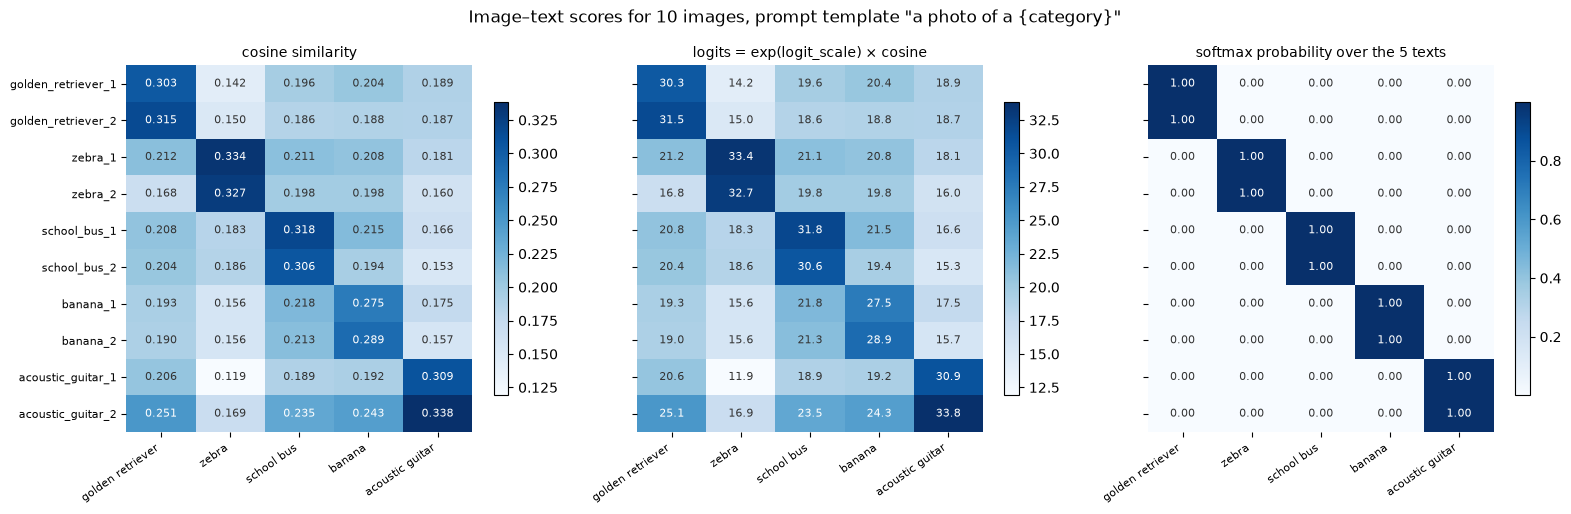

cosine range over all 20 x 5 pairs: 0.119 to 0.338
mean cosine, matching pairs: 0.308 | non-matching pairs: 0.187


In [7]:
def heatmap(ax, matrix, row_labels, col_labels, title, fmt="{:.2f}", fontsize=8, vmin=None, vmax=None):
    """Single-hue heatmap with the value written in each cell."""
    m = np.asarray(matrix)
    vmin = m.min() if vmin is None else vmin
    vmax = m.max() if vmax is None else vmax
    im = ax.imshow(m, cmap="Blues", vmin=vmin, vmax=vmax, aspect="auto")
    if fmt:
        mid = (vmin + vmax) / 2
        for (r, c), v in np.ndenumerate(m):
            ax.text(c, r, fmt.format(v), ha="center", va="center", fontsize=fontsize,
                    color="white" if v > mid else "#333333")
    ax.set_xticks(range(len(col_labels)), col_labels, rotation=35, ha="right", fontsize=8)
    ax.set_yticks(range(len(row_labels)), row_labels, fontsize=8)
    ax.set_title(title, fontsize=10)
    for s in ax.spines.values():
        s.set_visible(False)
    return im


subset = [i for c in CATEGORIES for i in np.where(sources.category == c)[0][:2]]
short = [NAMES[c] for c in CATEGORIES]
fig, axes = plt.subplots(1, 3, figsize=(16, 5.2))
panels = [(sim, "cosine similarity", "{:.3f}"), (logits, "logits = exp(logit_scale) × cosine", "{:.1f}"),
          (probs, "softmax probability over the 5 texts", "{:.2f}")]
for ax, (m, title, fmt) in zip(axes, panels):
    im = heatmap(ax, m[subset], [image_names[i] for i in subset], short, title, fmt)
    fig.colorbar(im, ax=ax, shrink=0.8)
for ax in axes[1:]:
    ax.set_yticklabels([])
fig.suptitle('Image–text scores for 10 images, prompt template "a photo of a {category}"')
plt.tight_layout()
plt.savefig(OUT / "task1_similarity_heatmap.png", dpi=150, bbox_inches="tight")
plt.show()

print(f"cosine range over all 20 x 5 pairs: {sim.min().item():.3f} to {sim.max().item():.3f}")
print(f"mean cosine, matching pairs: {sim[torch.arange(20), torch.from_numpy(true)].mean().item():.3f}"
      f" | non-matching pairs: {(sim.sum() - sim[torch.arange(20), torch.from_numpy(true)].sum()).item() / 80:.3f}")

### Probabilities depend on which texts you offer

One image scored against three candidate lists: the cosine and logit stay the same, but the probability changes.

In [8]:
demo_idx = image_names.index("golden_retriever_4")
candidate_sets = {
    "A: the 5 project categories": prompts,
    "B: only 2 candidates": ["a photo of a golden retriever", "a photo of a zebra"],
    "C: 5 categories + 2 similar dogs": prompts + ["a photo of a labrador retriever", "a photo of a kuvasz"],
}
rows = []
for name, cands in candidate_sets.items():
    s, l, p, _ = classify(image_emb[demo_idx:demo_idx + 1], encode_texts(cands))
    for j, text in enumerate(cands):
        rows.append({"candidate set": name, "text": text, "cosine": round(s[0, j].item(), 4),
                     "logit": round(l[0, j].item(), 2), "probability": round(p[0, j].item(), 4)})
cand_table = pd.DataFrame(rows)
cand_table.to_csv(OUT / "task1_candidate_set_demo.csv", index=False)
print("image:", image_names[demo_idx])
cand_table

image: golden_retriever_4


,candidate set,text,cosine,logit,probability
0,A: the 5 project categories,a photo of a golden retriever,0.3092,30.92,1.0000
1,A: the 5 project categories,a photo of a zebra,0.1652,16.52,0.0000
2,A: the 5 project categories,a photo of a school bus,0.1872,18.72,0.0000
3,A: the 5 project categories,a photo of a banana,0.1900,19.00,0.0000
4,A: the 5 project categories,a photo of an acoustic guitar,0.1684,16.84,0.0000
5,B: only 2 candidates,a photo of a golden retriever,0.3092,30.92,1.0000
6,B: only 2 candidates,a photo of a zebra,0.1652,16.52,0.0000
7,C: 5 categories + 2 similar dogs,a photo of a golden retriever,0.3092,30.92,0.7045
8,C: 5 categories + 2 similar dogs,a photo of a zebra,0.1652,16.52,0.0000
9,C: 5 categories + 2 similar dogs,a photo of a school bus,0.1872,18.72,0.0000


### Cosine similarities, logits, and probabilities

Logits are just cosines × 100, and softmax turns them into probabilities that only mean "best of these options". See the report for the full discussion.

## Task 2 — Compare prompt wording

Three prompt templates, with the model unchanged.

In [9]:
TEMPLATES = {
    "{category}": lambda n: n,
    "a photo of a {category}": lambda n: f"a photo of {article(n)} {n}",
    "an image showing a {category}": lambda n: f"an image showing {article(n)} {n}",
}

results = {}
for t_name, fill in TEMPLATES.items():
    texts = [fill(NAMES[c]) for c in CATEGORIES]
    s, l, p, yhat = classify(image_emb, encode_texts(texts))
    results[t_name] = {"texts": texts, "sim": s, "logits": l, "probs": p, "pred": yhat.numpy()}
    print(f"{t_name!r:34s} texts: {texts}")

np.savez(OUT / "task2_scores.npz", **{f"{k}|{m}": v[m].numpy() for k, v in results.items() for m in ("sim", "logits", "probs")})

'{category}'                       texts: ['golden retriever', 'zebra', 'school bus', 'banana', 'acoustic guitar']
'a photo of a {category}'          texts: ['a photo of a golden retriever', 'a photo of a zebra', 'a photo of a school bus', 'a photo of a banana', 'a photo of an acoustic guitar']
'an image showing a {category}'    texts: ['an image showing a golden retriever', 'an image showing a zebra', 'an image showing a school bus', 'an image showing a banana', 'an image showing an acoustic guitar']


In [10]:
acc_rows, cms = [], {}
for t_name, r in results.items():
    correct = r["pred"] == true
    cm = np.zeros((5, 5), dtype=int)
    for t, p in zip(true, r["pred"]):
        cm[t, p] += 1
    cms[t_name] = cm
    acc_rows.append({
        "template": t_name,
        "correct": int(correct.sum()),
        "n": len(true),
        "accuracy": correct.mean(),
        "mean prob. of true category": r["probs"][np.arange(20), true].mean().item(),
        "min prob. of true category": r["probs"][np.arange(20), true].min().item(),
        "mean cosine to true text": r["sim"][np.arange(20), true].mean().item(),
    })
    pd.DataFrame(cm, index=short, columns=short).to_csv(OUT / f"task2_confusion_{list(results).index(t_name) + 1}.csv")
acc_table = pd.DataFrame(acc_rows).round(4)
acc_table.to_csv(OUT / "task2_accuracy_by_template.csv", index=False)
acc_table

,template,correct,n,accuracy,mean prob. of true category,min prob. of true category,mean cosine to true text
0,{category},20,20,1.0,0.9998,0.9987,0.2963
1,a photo of a {category},20,20,1.0,0.9991,0.9918,0.3081
2,an image showing a {category},20,20,1.0,0.9998,0.9968,0.3145


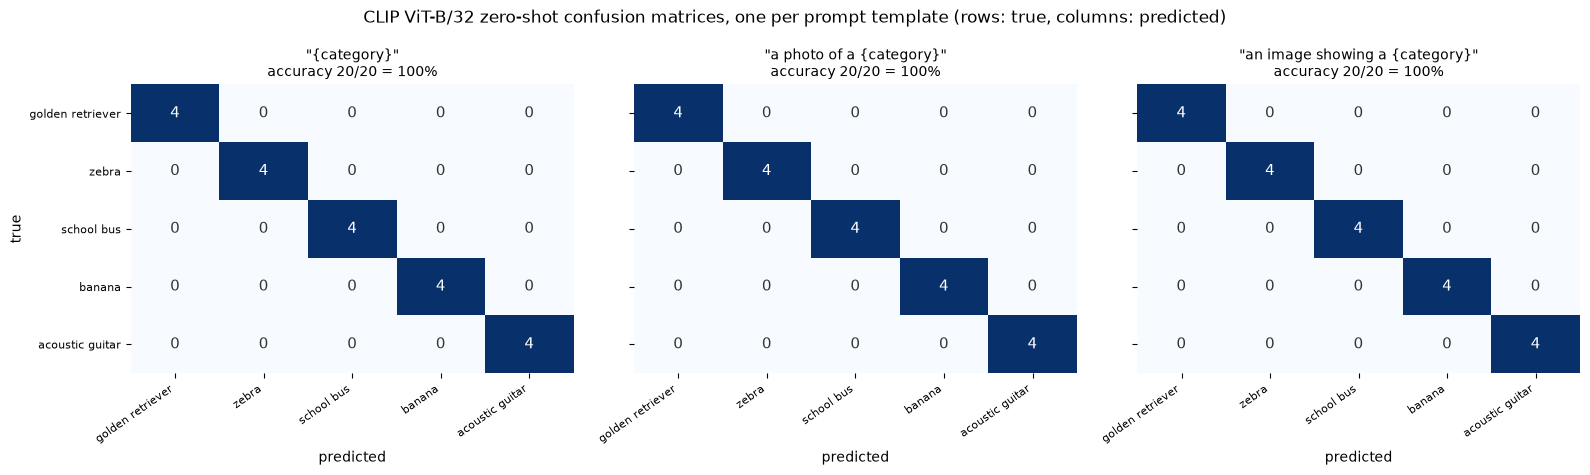

In [11]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4.8))
for ax, (t_name, cm) in zip(axes, cms.items()):
    heatmap(ax, cm, short, short, f'"{t_name}"\naccuracy {np.trace(cm)}/{cm.sum()} = {np.trace(cm) / cm.sum():.0%}',
            fmt="{:d}", fontsize=11, vmin=0, vmax=4)
    ax.set_xlabel("predicted")
axes[0].set_ylabel("true")
for ax in axes[1:]:
    ax.set_yticklabels([])
fig.suptitle("CLIP ViT-B/32 zero-shot confusion matrices, one per prompt template (rows: true, columns: predicted)")
plt.tight_layout()
plt.savefig(OUT / "task2_confusion_matrices.png", dpi=150, bbox_inches="tight")
plt.show()

### Where the wording changes a prediction or its score

The logit margin (right text minus best wrong text) for each image and template, sorted by how much it changes.

In [12]:
t_names = list(results)
per_image = pd.DataFrame({"image": image_names, "true": [NAMES[c] for c in sources.category]})
for k, t_name in enumerate(t_names, start=1):
    r = results[t_name]
    per_image[f"T{k} pred"] = [short[j] for j in r["pred"]]
    per_image[f"T{k} p(true)"] = r["probs"][np.arange(20), true].numpy().round(4)
    per_image[f"T{k} cos(true)"] = r["sim"][np.arange(20), true].numpy().round(4)
    wrong = r["logits"].clone()
    wrong[np.arange(20), true] = -float("inf")
    per_image[f"T{k} margin"] = (r["logits"][np.arange(20), true] - wrong.max(1).values).numpy().round(2)
m_cols = [f"T{k} margin" for k in (1, 2, 3)]
per_image["margin range"] = (per_image[m_cols].max(1) - per_image[m_cols].min(1)).round(2)
per_image["prediction changes"] = per_image[[f"T{k} pred" for k in (1, 2, 3)]].nunique(axis=1) > 1
per_image.to_csv(OUT / "task2_per_image_by_template.csv", index=False)

print("T1 =", t_names[0], "| T2 =", t_names[1], "| T3 =", t_names[2])
print("images whose predicted category changes with the wording:", int(per_image["prediction changes"].sum()))
with pd.option_context("display.width", 250):
    display(per_image.sort_values("margin range", ascending=False).reset_index(drop=True))

print("\nmean logit margin per template:")
print(per_image[m_cols].mean().round(2).to_string())
print("\nmean logit margin per category and template:")
print(per_image.groupby("true", sort=False)[m_cols].mean().round(2).to_string())

T1 = {category} | T2 = a photo of a {category} | T3 = an image showing a {category}
images whose predicted category changes with the wording: 0


,image,true,T1 pred,T1 p(true),T1 cos(true),T1 margin,T2 pred,T2 p(true),T2 cos(true),T2 margin,T3 pred,T3 p(true),T3 cos(true),T3 margin,margin range,prediction changes
0,zebra_4,zebra,zebra,0.9999,0.2945,9.20,zebra,1.0000,0.3200,11.24,zebra,1.0000,0.3337,12.62,3.42,False
1,banana_1,banana,banana,0.9998,0.2735,8.62,banana,0.9962,0.2745,5.67,banana,0.9994,0.2834,7.48,2.95,False
2,school_bus_2,school bus,school bus,0.9998,0.2852,9.18,school bus,0.9999,0.3062,10.22,school bus,1.0000,0.3197,12.12,2.94,False
3,school_bus_1,school bus,school bus,0.9998,0.2944,8.89,school bus,0.9999,0.3184,10.34,school bus,1.0000,0.3184,11.41,2.52,False
4,banana_3,banana,banana,0.9989,0.2842,6.92,banana,0.9961,0.2819,5.61,banana,0.9996,0.2905,7.93,2.32,False
5,golden_retriever_2,golden retriever,golden retriever,1.0000,0.3024,10.64,golden retriever,1.0000,0.3154,12.77,golden retriever,1.0000,0.3314,11.69,2.13,False
6,banana_2,banana,banana,0.9999,0.2968,9.64,banana,0.9994,0.2886,7.54,banana,0.9999,0.2984,9.60,2.10,False
7,acoustic_guitar_4,acoustic guitar,acoustic guitar,0.9998,0.3032,8.66,acoustic guitar,0.9999,0.3211,10.69,acoustic guitar,1.0000,0.3251,10.48,2.03,False
8,zebra_2,zebra,zebra,1.0000,0.3023,11.01,zebra,1.0000,0.3274,12.96,zebra,1.0000,0.3342,12.41,1.95,False
9,banana_4,banana,banana,0.9987,0.2635,6.80,banana,0.9918,0.2685,4.86,banana,0.9968,0.2876,5.77,1.94,False



mean logit margin per template:
T1 margin     9.64
T2 margin     9.96
T3 margin    10.48

mean logit margin per category and template:
                  T1 margin  T2 margin  T3 margin
true                                             
golden retriever      10.45      11.46      10.95
zebra                 10.52      12.04      12.11
school bus             9.89      10.44      11.86
banana                 8.00       5.92       7.70
acoustic guitar        9.34       9.94       9.79


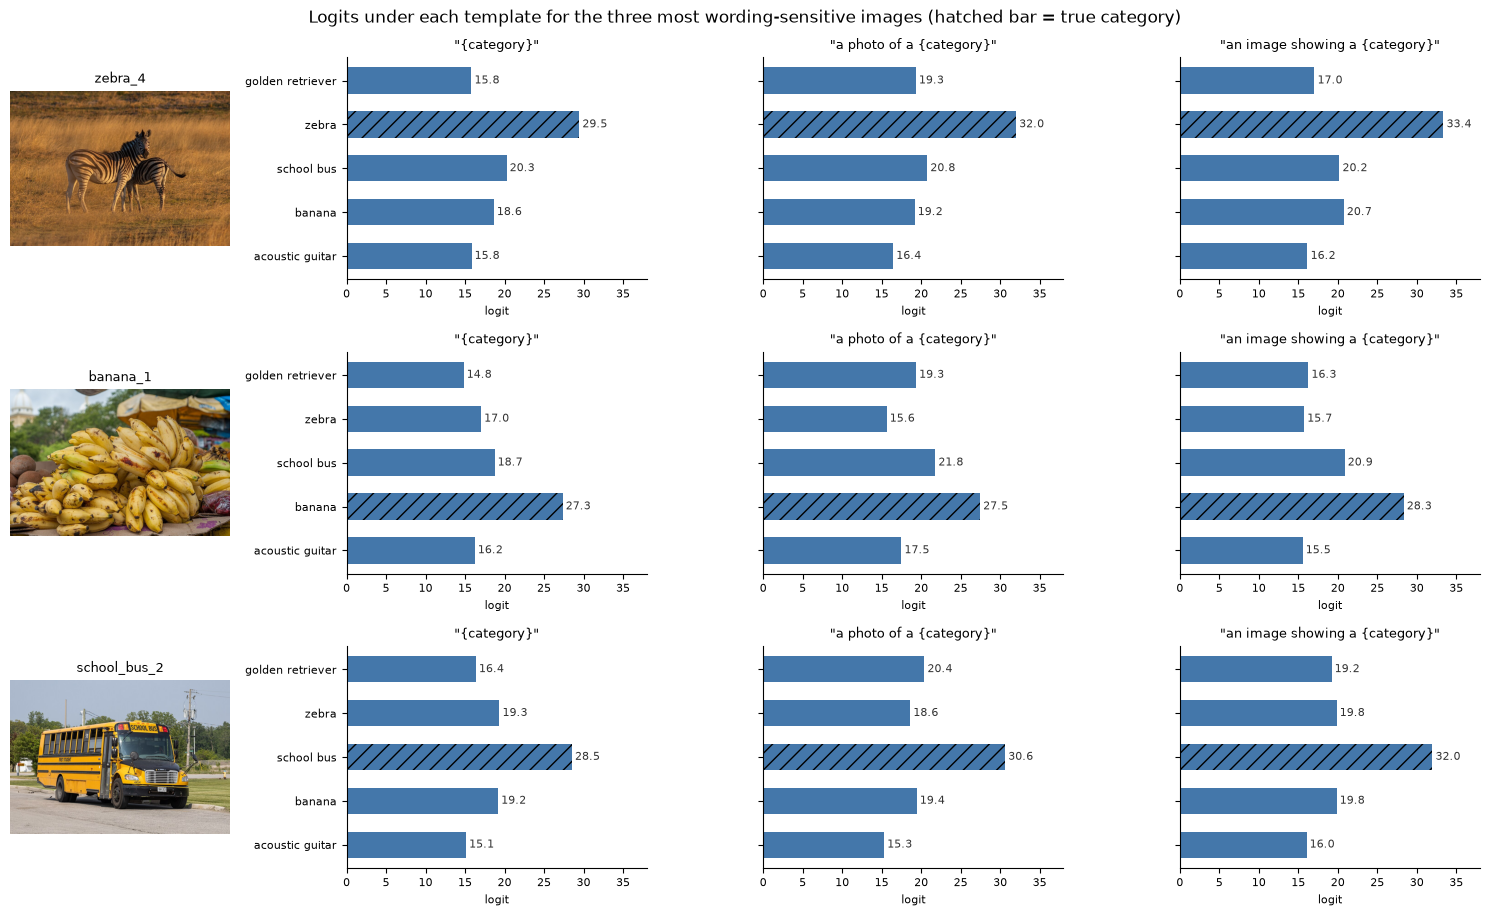

In [13]:
# Logits for all five texts, for the three images whose margin changes most with the wording
affected = per_image.sort_values("margin range", ascending=False).image.head(3).tolist()
fig, axes = plt.subplots(len(affected), 4, figsize=(15, 3.1 * len(affected)),
                         gridspec_kw={"width_ratios": [1.1, 1.5, 1.5, 1.5]})
for row_axes, name in zip(axes, affected):
    i = image_names.index(name)
    row_axes[0].imshow(Image.open(ROOT / sources.file[i]).convert("RGB"))
    row_axes[0].set_title(name, fontsize=9)
    row_axes[0].axis("off")
    for ax, t_name in zip(row_axes[1:], t_names):
        p = results[t_name]["logits"][i].numpy()
        bars = ax.barh(short, p, color="#4477aa", height=0.6)
        bars[true[i]].set_hatch("//")  # hatch marks the true category, so it is not colour-only
        for y, v in enumerate(p):
            ax.text(v + 0.4, y, f"{v:.1f}", va="center", fontsize=8, color="#333333")
        ax.set_xlim(0, 38)
        ax.set_xlabel("logit", fontsize=8)
        ax.invert_yaxis()
        ax.set_title(f'"{t_name}"', fontsize=9)
        ax.tick_params(labelsize=8)
        for s in ("top", "right"):
            ax.spines[s].set_visible(False)
    for ax in row_axes[2:]:
        ax.set_yticklabels([])
fig.suptitle("Logits under each template for the three most wording-sensitive images (hatched bar = true category)")
plt.tight_layout()
plt.savefig(OUT / "task2_wording_examples.png", dpi=150, bbox_inches="tight")
plt.show()

### Extra check: the same templates with harder choices

Adds one look-alike option per category (10 texts) to see whether wording can change a prediction.

In [14]:
DISTRACTORS = ["labrador retriever", "horse", "city bus", "plantain", "electric guitar"]
cand_names = short + DISTRACTORS

hard = {}
for t_name, fill in TEMPLATES.items():
    s, l, p, yhat = classify(image_emb, encode_texts([fill(n) for n in cand_names]))
    hard[t_name] = {"logits": l, "probs": p, "pred": yhat.numpy()}

hard_table = pd.DataFrame({"image": image_names, "true": [NAMES[c] for c in sources.category]})
for k, t_name in enumerate(TEMPLATES, start=1):
    h = hard[t_name]
    hard_table[f"T{k} pred"] = [cand_names[j] for j in h["pred"]]
    hard_table[f"T{k} p(true)"] = h["probs"][np.arange(20), true].numpy().round(3)
hard_table["prediction changes"] = hard_table[[f"T{k} pred" for k in (1, 2, 3)]].nunique(axis=1) > 1
hard_table.to_csv(OUT / "task2_supplementary_10_candidates.csv", index=False)

for k, t_name in enumerate(TEMPLATES, start=1):
    print(f"T{k} {t_name!r:34s} 10-candidate accuracy: {(hard[t_name]['pred'] == true).sum()}/20")
print("images whose prediction changes with the wording:", int(hard_table["prediction changes"].sum()))
with pd.option_context("display.width", 250):
    display(hard_table)

T1 '{category}'                       10-candidate accuracy: 17/20
T2 'a photo of a {category}'          10-candidate accuracy: 16/20
T3 'an image showing a {category}'    10-candidate accuracy: 18/20
images whose prediction changes with the wording: 2


,image,true,T1 pred,T1 p(true),T2 pred,T2 p(true),T3 pred,T3 p(true),prediction changes
0,golden_retriever_1,golden retriever,golden retriever,0.927,golden retriever,0.873,golden retriever,0.950,False
1,golden_retriever_2,golden retriever,golden retriever,0.982,golden retriever,0.969,golden retriever,0.992,False
2,golden_retriever_3,golden retriever,golden retriever,0.976,golden retriever,0.952,golden retriever,0.982,False
3,golden_retriever_4,golden retriever,golden retriever,0.780,golden retriever,0.745,golden retriever,0.753,False
4,zebra_1,zebra,zebra,1.000,zebra,1.000,zebra,1.000,False
5,zebra_2,zebra,zebra,1.000,zebra,1.000,zebra,1.000,False
6,zebra_3,zebra,zebra,1.000,zebra,0.999,zebra,1.000,False
7,zebra_4,zebra,zebra,1.000,zebra,1.000,zebra,1.000,False
8,school_bus_1,school bus,school bus,0.970,school bus,0.963,school bus,0.988,False
9,school_bus_2,school bus,school bus,0.986,school bus,0.979,school bus,0.989,False


### Comparison with Part 1

Note that the ViT chooses from 1000 classes while CLIP chooses from only 5 texts.

In [15]:
p1 = pd.read_csv(ROOT / "outputs" / "part1" / "per_image_summary.csv")
assert list(p1.image.str.replace(".jpg", "", regex=False)) == image_names
compare = pd.DataFrame({
    "image": image_names,
    "ViT-B/16 top-1 (1000 classes)": p1.top1_label,
    "ViT correct": p1.top1_correct,
    "ViT p(true)": p1.true_label_prob,
})
for k, t_name in enumerate(t_names, start=1):
    compare[f"CLIP T{k} correct"] = results[t_name]["pred"] == true
compare["CLIP T2 p(true)"] = per_image["T2 p(true)"]
compare.to_csv(OUT / "task2_comparison_with_part1.csv", index=False)

print(f"ViT-B/16, 1000-way: {p1.top1_correct.sum()}/20")
for k, t_name in enumerate(t_names, start=1):
    print(f"CLIP ViT-B/32, 5-way, T{k} {t_name!r}: {(results[t_name]['pred'] == true).sum()}/20")

# For reference only: the ViT restricted to the same 5 candidates (argmax over its 5 relevant outputs)
vit_probs = np.load(ROOT / "outputs" / "part1" / "vit_probabilities.npy")
lm = pd.read_csv(ROOT / "outputs" / "part1" / "label_mapping.csv").set_index("category").imagenet_index
vit5 = vit_probs[:, [lm[c] for c in CATEGORIES]].argmax(1)
print(f"ViT-B/16 restricted to the same 5 classes: {(vit5 == true).sum()}/20")
compare

ViT-B/16, 1000-way: 19/20
CLIP ViT-B/32, 5-way, T1 '{category}': 20/20
CLIP ViT-B/32, 5-way, T2 'a photo of a {category}': 20/20
CLIP ViT-B/32, 5-way, T3 'an image showing a {category}': 20/20
ViT-B/16 restricted to the same 5 classes: 20/20


,image,ViT-B/16 top-1 (1000 classes),ViT correct,ViT p(true),CLIP T1 correct,CLIP T2 correct,CLIP T3 correct,CLIP T2 p(true)
0,golden_retriever_1,golden retriever,True,0.8947,True,True,True,0.9999
1,golden_retriever_2,golden retriever,True,0.8657,True,True,True,1.0000
2,golden_retriever_3,golden retriever,True,0.8597,True,True,True,1.0000
3,golden_retriever_4,golden retriever,True,0.4433,True,True,True,1.0000
4,zebra_1,zebra,True,0.8811,True,True,True,1.0000
5,zebra_2,zebra,True,0.8999,True,True,True,1.0000
6,zebra_3,zebra,True,0.8914,True,True,True,1.0000
7,zebra_4,zebra,True,0.8983,True,True,True,1.0000
8,school_bus_1,school bus,True,0.8973,True,True,True,0.9999
9,school_bus_2,school bus,True,0.8902,True,True,True,0.9999


### Task 2 discussion

All three templates get 20/20; wording only changes the margins here, and only changes predictions in the 10-option check. See the report for the full discussion.

## Task 3 — Explore the representation space

Image–image cosine similarity, grouped by category so each one forms a 4 × 4 block.

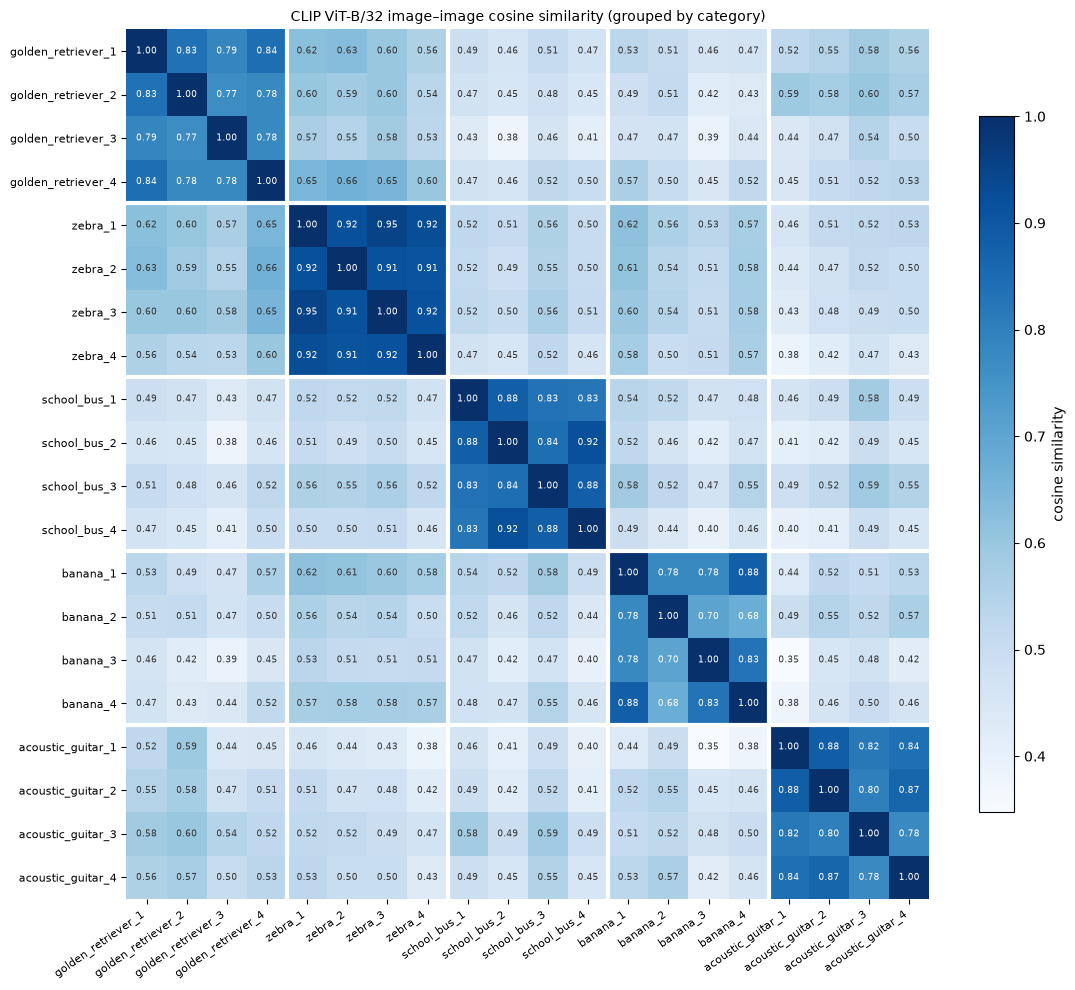

In [16]:
img_sim = cosine_similarity_matrix(image_emb, image_emb).numpy()
np.save(OUT / "task3_image_image_similarity.npy", img_sim)
pd.DataFrame(img_sim, index=image_names, columns=image_names).round(4).to_csv(OUT / "task3_image_image_similarity.csv")

off_diag = img_sim[~np.eye(20, dtype=bool)]
fig, ax = plt.subplots(figsize=(11.5, 10))
im = heatmap(ax, img_sim, image_names, image_names, "CLIP ViT-B/32 image–image cosine similarity (grouped by category)",
             fmt="{:.2f}", fontsize=6.5, vmin=off_diag.min(), vmax=1.0)
for k in range(4, 20, 4):  # separators between category blocks
    ax.axhline(k - 0.5, color="white", lw=3)
    ax.axvline(k - 0.5, color="white", lw=3)
fig.colorbar(im, ax=ax, shrink=0.8, label="cosine similarity")
plt.tight_layout()
plt.savefig(OUT / "task3_image_similarity_heatmap.png", dpi=150, bbox_inches="tight")
plt.show()

In [17]:
# Mean similarity within and between categories (the diagonal, an image with itself, is excluded)
block = np.zeros((5, 5))
for a in range(5):
    for b in range(5):
        sub = img_sim[np.ix_(true == a, true == b)]
        block[a, b] = sub[~np.eye(4, dtype=bool)].mean() if a == b else sub.mean()
block_df = pd.DataFrame(block, index=short, columns=short).round(3)
block_df.to_csv(OUT / "task3_category_block_means.csv")

same = true[:, None] == true[None, :]
upper = np.triu(np.ones((20, 20), dtype=bool), k=1)
within, between = img_sim[same & upper], img_sim[~same & upper]
print(f"within-category pairs:  n={within.size:3d}  mean={within.mean():.3f}  min={within.min():.3f}  max={within.max():.3f}")
print(f"between-category pairs: n={between.size:3d}  mean={between.mean():.3f}  min={between.min():.3f}  max={between.max():.3f}")
print(f"between-category pairs that score higher than the lowest within-category pair: {(between > within.min()).sum()}")

# nearest neighbour of each image: is it from the same category?
nn = np.where(np.eye(20, dtype=bool), -np.inf, img_sim).argmax(1)
print(f"images whose nearest neighbour is in the same category: {(true[nn] == true).sum()}/20")
block_df

within-category pairs:  n= 30  mean=0.838  min=0.676  max=0.951
between-category pairs: n=160  mean=0.505  min=0.347  max=0.661
between-category pairs that score higher than the lowest within-category pair: 0
images whose nearest neighbour is in the same category: 20/20


,golden retriever,zebra,school bus,banana,acoustic guitar
golden retriever,0.797,0.595,0.464,0.476,0.532
zebra,0.595,0.923,0.510,0.556,0.471
school bus,0.464,0.510,0.864,0.487,0.481
banana,0.476,0.556,0.487,0.774,0.476
acoustic guitar,0.532,0.471,0.481,0.476,0.831


In [18]:
pairs = pd.DataFrame([{"image A": image_names[i], "image B": image_names[j], "cosine": round(float(img_sim[i, j]), 4),
                       "same category": bool(same[i, j])} for i in range(20) for j in range(i + 1, 20)])
pairs.to_csv(OUT / "task3_all_pairs.csv", index=False)

top_within = pairs[pairs["same category"]].nlargest(5, "cosine")
low_within = pairs[pairs["same category"]].nsmallest(5, "cosine")
top_cross = pairs[~pairs["same category"]].nlargest(6, "cosine")
low_cross = pairs[~pairs["same category"]].nsmallest(3, "cosine")
print("Most similar pairs within a category");  display(top_within)
print("Least similar pairs within a category"); display(low_within)
print("Most similar pairs across categories");  display(top_cross)
print("Least similar pairs across categories"); display(low_cross)

Most similar pairs within a category


,image A,image B,cosine,same category
71,zebra_1,zebra_3,0.9509,True
72,zebra_1,zebra_4,0.9243,True
70,zebra_1,zebra_2,0.9203,True
136,school_bus_2,school_bus_4,0.9194,True
99,zebra_3,zebra_4,0.9160,True


Least similar pairs within a category


,image A,image B,cosine,same category
170,banana_2,banana_4,0.6755,True
169,banana_2,banana_3,0.7029,True
19,golden_retriever_2,golden_retriever_3,0.7670,True
189,acoustic_guitar_3,acoustic_guitar_4,0.7750,True
37,golden_retriever_3,golden_retriever_4,0.7761,True


Most similar pairs across categories


,image A,image B,cosine,same category
55,golden_retriever_4,zebra_2,0.6610,False
56,golden_retriever_4,zebra_3,0.6531,False
54,golden_retriever_4,zebra_1,0.6497,False
4,golden_retriever_1,zebra_2,0.6287,False
3,golden_retriever_1,zebra_1,0.6214,False
77,zebra_1,banana_1,0.6156,False


Least similar pairs across categories


,image A,image B,cosine,same category
176,banana_3,acoustic_guitar_1,0.3475,False
180,banana_4,acoustic_guitar_1,0.3784,False
43,golden_retriever_3,school_bus_2,0.3793,False


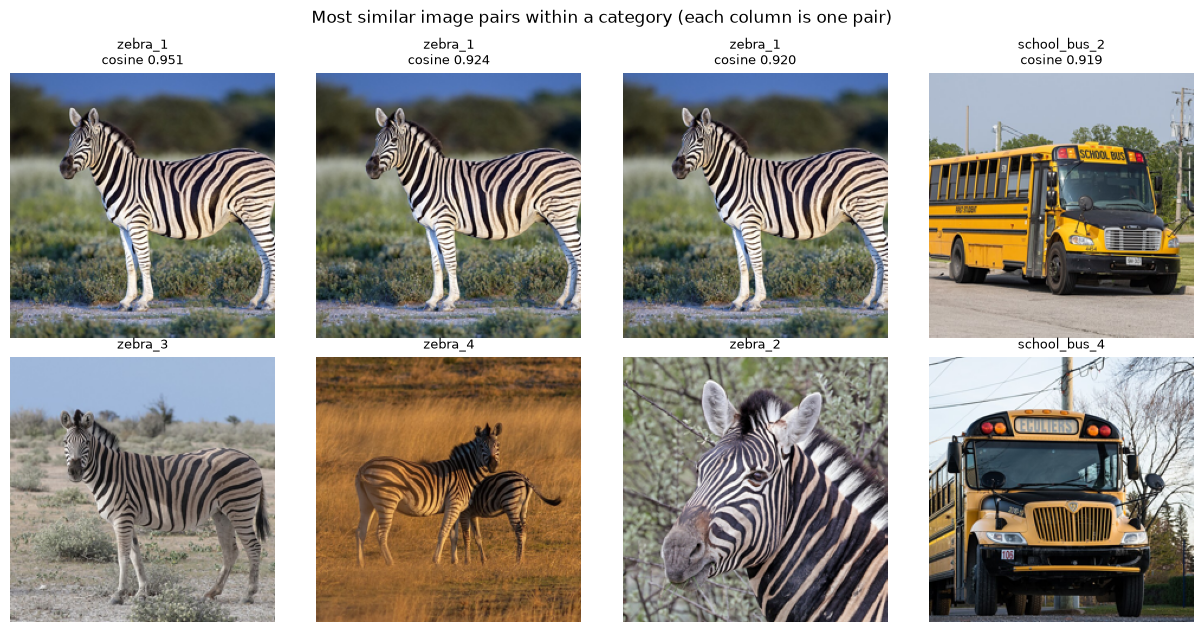

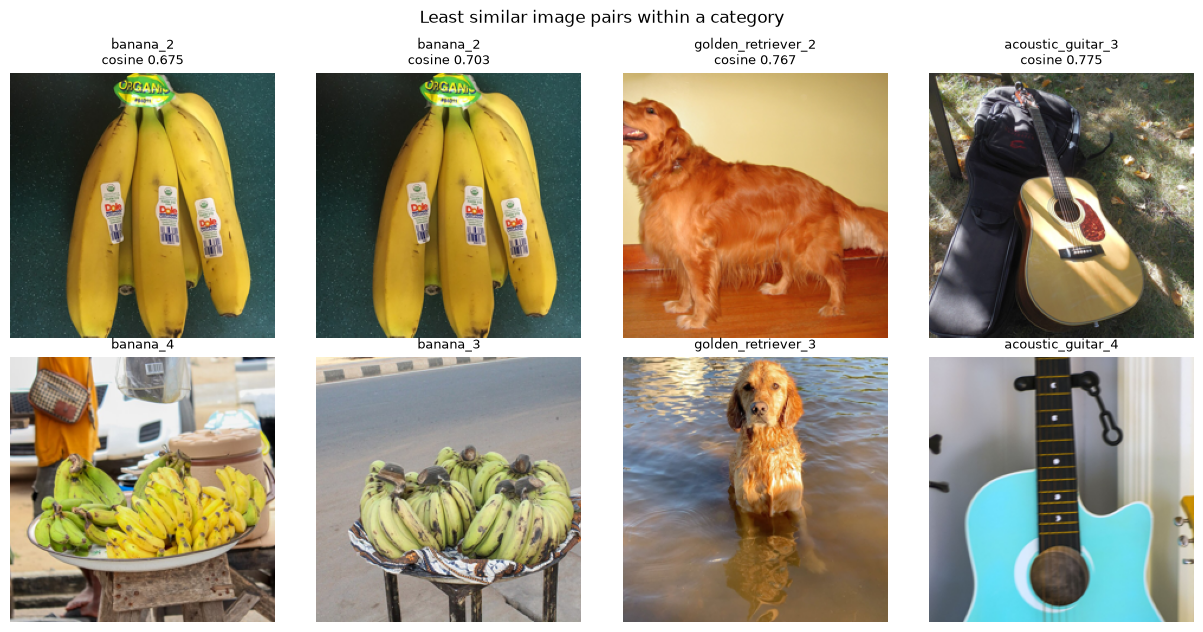

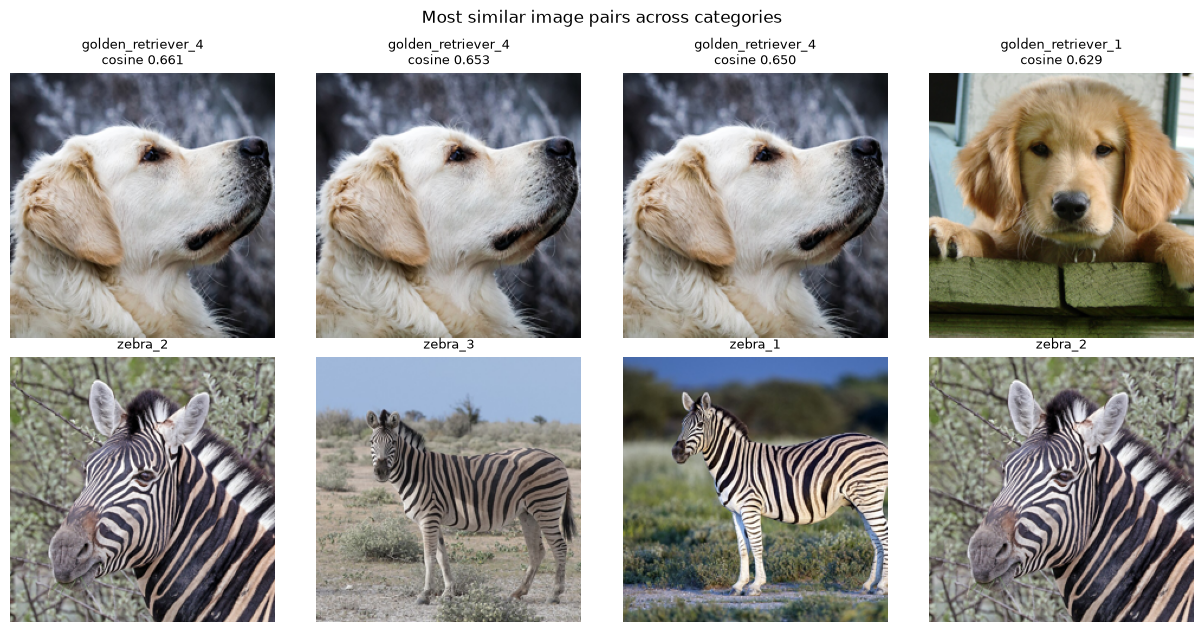

In [19]:
def show_pairs(df, title, path):
    fig, axes = plt.subplots(2, len(df), figsize=(3.1 * len(df), 6.4))
    for col, (_, r) in enumerate(df.iterrows()):
        for row, key in enumerate(("image A", "image B")):
            i = image_names.index(r[key])
            axes[row, col].imshow(ImageOps.fit(Image.open(ROOT / sources.file[i]).convert("RGB"), (224, 224)))  # centre crop, as the model sees it
            axes[row, col].set_title(r[key] + (f"\ncosine {r.cosine:.3f}" if row == 0 else ""), fontsize=9)
            axes[row, col].axis("off")
    fig.suptitle(title)
    plt.tight_layout()
    plt.savefig(path, dpi=130, bbox_inches="tight")
    plt.show()


show_pairs(top_within.head(4), "Most similar image pairs within a category (each column is one pair)", OUT / "task3_pairs_within_high.png")
show_pairs(low_within.head(4), "Least similar image pairs within a category", OUT / "task3_pairs_within_low.png")
show_pairs(top_cross.head(4), "Most similar image pairs across categories", OUT / "task3_pairs_cross_high.png")

### Task 3 discussion

Every image's closest match is from its own category (20/20), but colour, setting, and layout also affect similarity. See the report for the full discussion.